
# Swanson Stream LSTM — High-Water-Risk Classification

This notebook develops a **Swanson Stream-specific LSTM** using the same methodology applied to Mahurangi and Otara.

### Objective
Use the previous **48 hours** of:

- `rainfall_mm`
- `discharge_m3s`
- `water_level_m`

to estimate whether the water level will exceed a **catchment-specific high-water-risk threshold during the next 24 hours**.

### Methodological consistency
- Chronological train / validation / test split.
- High-water threshold = **99.5th percentile of training-period water level only**.
- 48-hour LSTM input window.
- 24-hour forecast horizon.
- Missing input values are not interpolated; invalid sequences are excluded.
- Class imbalance is handled with `pos_weight`.
- Probability threshold is selected on validation data using F2-score.
- Test data remain untouched until final evaluation.

The target is a **statistical high-water-risk proxy**, not an independently verified historical flood label.



## 1. Libraries 


In [1]:

import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

import joblib
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.14.1+cpu
CUDA available: False


## 2. Load Swanson Water-Level/Rainfall Data and Discharge Station 7907

In [2]:

swanson_path = Path("swanson_cleaned_hourly.csv")
discharge_path = Path("7907.csv")

if not swanson_path.exists():
    raise FileNotFoundError(
        "swanson_cleaned_hourly.csv was not found. "
        "Place it in the same folder as this notebook."
    )

if not discharge_path.exists():
    raise FileNotFoundError(
        "7907.csv was not found. "
        "Place it in the same folder as this notebook."
    )

swanson_raw = pd.read_csv(swanson_path)

required_swanson_columns = [
    "start_time",
    "rainfall_mm",
    "water_level_m",
]

missing_swanson_columns = [
    col for col in required_swanson_columns
    if col not in swanson_raw.columns
]

if missing_swanson_columns:
    raise ValueError(
        f"Missing required Swanson columns: {missing_swanson_columns}"
    )

swanson_base = swanson_raw[
    required_swanson_columns
].copy()

swanson_base["start_time"] = pd.to_datetime(
    swanson_base["start_time"],
    errors="coerce"
)

# The supplied cleaned file contains one duplicate midnight row
# on 1 January in several years. The duplicated core measurements
# are identical, so one copy is retained.
duplicate_count = swanson_base["start_time"].duplicated().sum()

swanson_base = (
    swanson_base
    .drop_duplicates(
        subset=["start_time"],
        keep="first"
    )
    .sort_values("start_time")
    .reset_index(drop=True)
)

print("Duplicate timestamps removed:", duplicate_count)

# The 7907 export has a metadata row before its true header.
discharge = pd.read_csv(
    discharge_path,
    skiprows=1
)

discharge = discharge.iloc[:, :3].copy()
discharge.columns = [
    "start_time",
    "end_time",
    "discharge_m3s",
]

discharge["start_time"] = pd.to_datetime(
    discharge["start_time"],
    errors="coerce"
)

discharge["discharge_m3s"] = pd.to_numeric(
    discharge["discharge_m3s"],
    errors="coerce"
)

discharge = (
    discharge[
        [
            "start_time",
            "discharge_m3s"
        ]
    ]
    .drop_duplicates(
        subset=["start_time"],
        keep="first"
    )
)

df = (
    swanson_base
    .merge(
        discharge,
        on="start_time",
        how="left"
    )
    .rename(
        columns={
            "start_time": "timestamp"
        }
    )
    [
        [
            "timestamp",
            "rainfall_mm",
            "discharge_m3s",
            "water_level_m",
        ]
    ]
    .sort_values("timestamp")
    .reset_index(drop=True)
)

display(df.head())


Duplicate timestamps removed: 10


,timestamp,rainfall_mm,discharge_m3s,water_level_m
0,2015-01-01 06:00:00,0.0,0.227,0.354
1,2015-01-01 07:00:00,0.0,0.220,0.351
2,2015-01-01 08:00:00,0.0,0.216,0.349
3,2015-01-01 09:00:00,0.0,0.225,0.353
4,2015-01-01 10:00:00,0.0,0.227,0.354



### Export the Consolidated Swanson Hourly Dataset

The rainfall/water-level dataset and station 7907 discharge data are now combined into one reusable hourly dataset.

This file is exported **before LSTM-specific processing** so it can also be used by other team members for Random Forest, XGBoost, or other modelling approaches.

The exported file contains:

- `timestamp`
- `rainfall_mm`
- `discharge_m3s`
- `water_level_m`

The original source files are not modified.


In [3]:

consolidated_dataset_path = Path(
    "swanson_lstm_hourly.csv"
)

df.to_csv(
    consolidated_dataset_path,
    index=False
)

print(
    "Consolidated Swanson hourly dataset saved as:",
    consolidated_dataset_path.resolve()
)

print("\nShape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Consolidated Swanson hourly dataset saved as: C:\Users\lauso\AA Capstone Project\swanson_lstm_hourly.csv

Shape: (96423, 4)

Columns:
['timestamp', 'rainfall_mm', 'discharge_m3s', 'water_level_m']


,timestamp,rainfall_mm,discharge_m3s,water_level_m
0,2015-01-01 06:00:00,0.0,0.227,0.354
1,2015-01-01 07:00:00,0.0,0.220,0.351
2,2015-01-01 08:00:00,0.0,0.216,0.349
3,2015-01-01 09:00:00,0.0,0.225,0.353
4,2015-01-01 10:00:00,0.0,0.227,0.354


## 3. Audit the Combined Hourly Series

In [4]:

print("Shape:", df.shape)

print("\nDate range:")
print(df["timestamp"].min(), "to", df["timestamp"].max())

print("\nDuplicate timestamps:")
print(df["timestamp"].duplicated().sum())

print("\nMissing values:")
print(df.isna().sum())

time_difference = df["timestamp"].diff()

non_hourly_gap = (
    time_difference.notna()
    & (
        time_difference
        != pd.Timedelta(hours=1)
    )
)

print("\nNumber of non-hourly gaps:")
print(non_hourly_gap.sum())

if non_hourly_gap.sum() > 0:
    display(
        df.loc[
            non_hourly_gap,
            ["timestamp"]
        ].head(20)
    )


Shape: (96423, 4)

Date range:
2015-01-01 06:00:00 to 2025-12-31 20:00:00

Duplicate timestamps:
0

Missing values:
timestamp          0
rainfall_mm        0
discharge_m3s    127
water_level_m      0
dtype: int64

Number of non-hourly gaps:
0



## 4. Chronological Train / Validation / Test Split

The cleaned Swanson series runs continuously from early 2015 to the end of 2025.

The same 70% / 15% / 15% chronological split strategy used for the other catchments is applied here.


In [5]:

model_data = df.copy()

number_of_rows = len(model_data)

train_end = int(number_of_rows * 0.70)
validation_end = int(number_of_rows * 0.85)

model_data["data_period"] = "test"

model_data.loc[
    model_data.index < train_end,
    "data_period"
] = "train"

model_data.loc[
    (model_data.index >= train_end)
    & (model_data.index < validation_end),
    "data_period"
] = "validation"

split_summary = (
    model_data
    .groupby("data_period")
    .agg(
        rows=("timestamp", "size"),
        beginning=("timestamp", "min"),
        ending=("timestamp", "max"),
    )
    .loc[
        ["train", "validation", "test"]
    ]
)

display(split_summary)


,rows,beginning,ending
data_period,,,
train,67496,2015-01-01 06:00:00,2022-09-13 13:00:00
validation,14463,2022-09-13 14:00:00,2024-05-08 04:00:00
test,14464,2024-05-08 05:00:00,2025-12-31 20:00:00


## 5. Define the Statistical High-Water-Risk Target

In [6]:

HIGH_WATER_PERCENTILE = 0.995

high_water_threshold = (
    model_data.loc[
        model_data["data_period"] == "train",
        "water_level_m"
    ]
    .dropna()
    .quantile(HIGH_WATER_PERCENTILE)
)

print(
    "Training-only 99.5th percentile high-water threshold:",
    round(high_water_threshold, 3),
    "m"
)


Training-only 99.5th percentile high-water threshold: 1.108 m


In [7]:

FORECAST_HORIZON = 24

future_water_levels = pd.concat(
    [
        model_data["water_level_m"].shift(-hour)
        for hour in range(
            1,
            FORECAST_HORIZON + 1
        )
    ],
    axis=1
)

# Require every future water-level observation to be available.
model_data["future_24h_max_water_level"] = (
    future_water_levels.max(
        axis=1,
        skipna=False
    )
)

model_data["flood_next_24h"] = np.where(
    model_data[
        "future_24h_max_water_level"
    ].isna(),
    np.nan,
    (
        model_data[
            "future_24h_max_water_level"
        ]
        >= high_water_threshold
    ).astype(int)
)

# Prevent a target from crossing from one data period into another.
future_periods = pd.concat(
    [
        model_data["data_period"].shift(-hour)
        for hour in range(
            1,
            FORECAST_HORIZON + 1
        )
    ],
    axis=1
)

same_period_target = future_periods.eq(
    model_data["data_period"],
    axis=0
).all(axis=1)

model_data.loc[
    ~same_period_target,
    [
        "future_24h_max_water_level",
        "flood_next_24h",
    ]
] = np.nan

print(
    "Rows with unavailable or boundary-crossing targets:",
    model_data["flood_next_24h"].isna().sum()
)


Rows with unavailable or boundary-crossing targets: 72


In [8]:

target_summary = (
    model_data
    .dropna(
        subset=["flood_next_24h"]
    )
    .groupby("data_period")[
        "flood_next_24h"
    ]
    .agg(
        total_rows="count",
        high_water_risk_hours="sum",
        high_water_risk_percentage="mean",
    )
    .loc[
        ["train", "validation", "test"]
    ]
)

target_summary[
    "high_water_risk_percentage"
] *= 100

display(
    target_summary.round(3)
)


,total_rows,high_water_risk_hours,high_water_risk_percentage
data_period,,,
train,67472,1767.0,2.619
validation,14439,527.0,3.650
test,14440,441.0,3.054



## 6. Missing Input Data

No interpolation is performed.

A sequence is valid only when all 48 historical hours contain rainfall, discharge, and water-level measurements.


In [9]:

feature_columns = [
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m",
]

model_data["features_available"] = (
    model_data[
        feature_columns
    ]
    .notna()
    .all(axis=1)
)

missing_rows = (
    ~model_data["features_available"]
)

print(
    "Rows with at least one missing input:",
    missing_rows.sum()
)

missing_groups = (
    missing_rows
    .ne(
        missing_rows.shift(
            fill_value=False
        )
    )
    .cumsum()
)

missing_episodes = (
    model_data.loc[missing_rows]
    .assign(
        missing_group=missing_groups[
            missing_rows
        ]
    )
    .groupby("missing_group")
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        hours=("timestamp", "size"),
    )
    .reset_index(drop=True)
)

print(
    "Missing-data episodes:",
    len(missing_episodes)
)

if len(missing_episodes) > 0:
    print(
        "Longest missing-data episode:",
        missing_episodes["hours"].max(),
        "hours"
    )

    display(
        missing_episodes.head(20)
    )


Rows with at least one missing input: 127
Missing-data episodes: 28
Longest missing-data episode: 33 hours


,start,end,hours
0,2016-02-17 09:00:00,2016-02-17 13:00:00,5
1,2017-01-19 08:00:00,2017-01-19 09:00:00,2
2,2017-07-13 11:00:00,2017-07-13 13:00:00,3
3,2018-03-27 12:00:00,2018-03-27 12:00:00,1
4,2019-01-14 09:00:00,2019-01-14 10:00:00,2
5,2019-08-05 10:00:00,2019-08-05 11:00:00,2
6,2020-01-09 08:00:00,2020-01-09 09:00:00,2
7,2020-05-27 10:00:00,2020-05-27 13:00:00,4
8,2020-08-13 12:00:00,2020-08-14 01:00:00,14
9,2020-08-14 09:00:00,2020-08-14 16:00:00,8


## 7. LSTM Lookback

In [10]:

LOOKBACK_HOURS = 48

candidate_lookbacks = [
    24,
    48,
    72,
]

lookback_results = []

for lookback in candidate_lookbacks:

    valid_input_sequence = (
        model_data[
            "features_available"
        ]
        .astype(int)
        .rolling(
            window=lookback,
            min_periods=lookback
        )
        .sum()
        .eq(lookback)
    )

    valid_sample = (
        valid_input_sequence
        & model_data[
            "flood_next_24h"
        ].notna()
    )

    for period in [
        "train",
        "validation",
        "test"
    ]:

        lookback_results.append({
            "lookback_hours": lookback,
            "data_period": period,
            "valid_samples": int(
                (
                    valid_sample
                    & model_data[
                        "data_period"
                    ].eq(period)
                ).sum()
            )
        })

lookback_summary = pd.DataFrame(
    lookback_results
)

display(
    lookback_summary.pivot(
        index="lookback_hours",
        columns="data_period",
        values="valid_samples"
    )
)


data_period,test,train,validation
lookback_hours,,,
24,14266,67021,14306
48,14098,66637,14210
72,13930,66253,14114


## 8. Scale Inputs Using Training Data Only

In [11]:

scaler_fit_mask = (
    model_data[
        "data_period"
    ].eq("train")
    & model_data[
        "features_available"
    ]
)

scaler = StandardScaler()

scaler.fit(
    model_data.loc[
        scaler_fit_mask,
        feature_columns
    ]
)

scaled_features = scaler.transform(
    model_data[
        feature_columns
    ]
).astype(np.float32)

print("Training means:")
display(
    pd.Series(
        scaler.mean_,
        index=feature_columns
    ).to_frame(
        "mean"
    )
)

print("\nTraining scales:")
display(
    pd.Series(
        scaler.scale_,
        index=feature_columns
    ).to_frame(
        "scale"
    )
)


Training means:


,mean
rainfall_mm,0.156578
discharge_m3s,0.576686
water_level_m,0.384450



Training scales:


,scale
rainfall_mm,0.852765
discharge_m3s,2.040420
water_level_m,0.165547


## 9. Convert the Hourly Series into 3D LSTM Sequences

In [12]:

from numpy.lib.stride_tricks import sliding_window_view

def create_sequences(
    data,
    scaled_feature_array,
    lookback,
    period_name,
):
    targets = (
        data[
            "flood_next_24h"
        ]
        .to_numpy()
    )

    periods = (
        data[
            "data_period"
        ]
        .to_numpy()
    )

    feature_available = (
        np.isfinite(
            scaled_feature_array
        )
        .all(axis=1)
    )

    complete_window = (
        pd.Series(
            feature_available.astype(int)
        )
        .rolling(
            window=lookback,
            min_periods=lookback
        )
        .sum()
        .to_numpy()
        == lookback
    )

    valid_end = (
        complete_window
        & np.isfinite(targets)
        & (
            periods
            == period_name
        )
    )

    end_indices = np.where(
        valid_end
    )[0]

    all_windows = (
        sliding_window_view(
            scaled_feature_array,
            window_shape=lookback,
            axis=0
        )
        .transpose(
            0,
            2,
            1
        )
    )

    window_positions = (
        end_indices
        - (lookback - 1)
    )

    X = (
        all_windows[
            window_positions
        ]
        .copy()
        .astype(
            np.float32
        )
    )

    y = (
        targets[
            end_indices
        ]
        .astype(
            np.float32
        )
    )

    timestamps = (
        data.loc[
            end_indices,
            "timestamp"
        ]
        .to_numpy()
    )

    return (
        X,
        y,
        timestamps,
        end_indices,
    )


In [13]:

X_train, y_train, train_timestamps, train_indices = (
    create_sequences(
        model_data,
        scaled_features,
        LOOKBACK_HOURS,
        "train"
    )
)

X_validation, y_validation, validation_timestamps, validation_indices = (
    create_sequences(
        model_data,
        scaled_features,
        LOOKBACK_HOURS,
        "validation"
    )
)

print(
    "X_train:",
    X_train.shape
)
print(
    "y_train:",
    y_train.shape
)
print(
    "X_validation:",
    X_validation.shape
)
print(
    "y_validation:",
    y_validation.shape
)

print("\nPositive percentage:")
print(
    "Train:",
    round(
        y_train.mean() * 100,
        3
    ),
    "%"
)
print(
    "Validation:",
    round(
        y_validation.mean() * 100,
        3
    ),
    "%"
)


X_train: (66637, 48, 3)
y_train: (66637,)
X_validation: (14210, 48, 3)
y_validation: (14210,)

Positive percentage:
Train: 2.592 %
Validation: 3.568 %


## 10. Handle Class Imbalance

In [14]:

negative_count = int(
    (y_train == 0).sum()
)

positive_count = int(
    (y_train == 1).sum()
)

positive_weight = (
    negative_count
    / positive_count
)

print(
    "Negative samples:",
    negative_count
)

print(
    "Positive samples:",
    positive_count
)

print(
    "Positive class weight:",
    round(
        positive_weight,
        3
    )
)


Negative samples: 64910
Positive samples: 1727
Positive class weight: 37.585


## 11. LSTM Architecture

In [15]:

class LSTMClassifier(
    nn.Module
):
    def __init__(
        self,
        input_size=3,
        hidden_size=32,
        dense_size=16,
        dropout=0.25,
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True,
        )

        self.dropout = (
            nn.Dropout(
                dropout
            )
        )

        self.dense = nn.Linear(
            hidden_size,
            dense_size
        )

        self.relu = nn.ReLU()

        self.output = nn.Linear(
            dense_size,
            1
        )

    def forward(
        self,
        x
    ):
        _, (
            hidden_state,
            _
        ) = self.lstm(x)

        x = hidden_state[-1]

        x = self.dropout(x)
        x = self.dense(x)
        x = self.relu(x)

        logits = self.output(x)

        return logits.squeeze(1)


model = LSTMClassifier(
    input_size=len(
        feature_columns
    ),
    hidden_size=32,
    dense_size=16,
    dropout=0.25,
)

print(model)


LSTMClassifier(
  (lstm): LSTM(3, 32, batch_first=True)
  (dropout): Dropout(p=0.25, inplace=False)
  (dense): Linear(in_features=32, out_features=16, bias=True)
  (relu): ReLU()
  (output): Linear(in_features=16, out_features=1, bias=True)
)


## 12. Train the LSTM

In [16]:

torch.manual_seed(SEED)
np.random.seed(SEED)

BATCH_SIZE = 512
MAX_EPOCHS = 15
PATIENCE = 4
LEARNING_RATE = 0.001
MIN_DELTA = 1e-4

model = LSTMClassifier(
    input_size=len(
        feature_columns
    ),
    hidden_size=32,
    dense_size=16,
    dropout=0.25,
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

loss_function = (
    nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            positive_weight,
            dtype=torch.float32
        )
    )
)

train_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(
            X_train
        ),
        torch.from_numpy(
            y_train
        )
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

validation_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(
            X_validation
        ),
        torch.from_numpy(
            y_validation
        )
    ),
    batch_size=1024,
    shuffle=False,
)

best_validation_pr_auc = -np.inf
best_state = None
best_epoch = None
epochs_without_improvement = 0
training_history = []

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    model.train()

    total_loss = 0.0

    for (
        X_batch,
        y_batch
    ) in train_loader:

        optimizer.zero_grad()

        logits = model(
            X_batch
        )

        loss = loss_function(
            logits,
            y_batch
        )

        loss.backward()
        optimizer.step()

        total_loss += (
            loss.item()
            * len(y_batch)
        )

    epoch_loss = (
        total_loss
        / len(y_train)
    )

    model.eval()

    validation_probability_parts = []

    with torch.no_grad():

        for (
            X_batch,
            _
        ) in validation_loader:

            probabilities = torch.sigmoid(
                model(
                    X_batch
                )
            )

            validation_probability_parts.append(
                probabilities.cpu().numpy()
            )

    validation_probabilities = np.concatenate(
        validation_probability_parts
    )

    validation_pr_auc = (
        average_precision_score(
            y_validation,
            validation_probabilities
        )
    )

    validation_roc_auc = (
        roc_auc_score(
            y_validation,
            validation_probabilities
        )
    )

    training_history.append({
        "epoch": epoch,
        "train_loss": epoch_loss,
        "validation_pr_auc": validation_pr_auc,
        "validation_roc_auc": validation_roc_auc,
    })

    print(
        f"Epoch {epoch:02d} | "
        f"loss={epoch_loss:.4f} | "
        f"val_PR_AUC={validation_pr_auc:.4f} | "
        f"val_ROC_AUC={validation_roc_auc:.4f}"
    )

    if (
        validation_pr_auc
        > best_validation_pr_auc
        + MIN_DELTA
    ):
        best_validation_pr_auc = (
            validation_pr_auc
        )

        best_state = copy.deepcopy(
            model.state_dict()
        )

        best_epoch = epoch

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

        if (
            epochs_without_improvement
            >= PATIENCE
        ):
            print(
                "\nEarly stopping triggered."
            )
            break

model.load_state_dict(
    best_state
)

history_df = pd.DataFrame(
    training_history
)

print(
    "\nBest epoch:",
    best_epoch
)

print(
    "Best validation PR-AUC:",
    round(
        best_validation_pr_auc,
        4
    )
)


Epoch 01 | loss=1.2532 | val_PR_AUC=0.3778 | val_ROC_AUC=0.8519
Epoch 02 | loss=1.0854 | val_PR_AUC=0.4031 | val_ROC_AUC=0.8551
Epoch 03 | loss=1.0491 | val_PR_AUC=0.4113 | val_ROC_AUC=0.8564
Epoch 04 | loss=1.0389 | val_PR_AUC=0.4163 | val_ROC_AUC=0.8571
Epoch 05 | loss=1.0303 | val_PR_AUC=0.4194 | val_ROC_AUC=0.8570
Epoch 06 | loss=1.0243 | val_PR_AUC=0.4214 | val_ROC_AUC=0.8575
Epoch 07 | loss=1.0145 | val_PR_AUC=0.4227 | val_ROC_AUC=0.8579
Epoch 08 | loss=1.0330 | val_PR_AUC=0.4224 | val_ROC_AUC=0.8562
Epoch 09 | loss=1.0105 | val_PR_AUC=0.4234 | val_ROC_AUC=0.8580
Epoch 10 | loss=1.0267 | val_PR_AUC=0.4230 | val_ROC_AUC=0.8558
Epoch 11 | loss=1.0033 | val_PR_AUC=0.4242 | val_ROC_AUC=0.8579
Epoch 12 | loss=1.0127 | val_PR_AUC=0.4236 | val_ROC_AUC=0.8562
Epoch 13 | loss=1.0015 | val_PR_AUC=0.4242 | val_ROC_AUC=0.8573
Epoch 14 | loss=0.9971 | val_PR_AUC=0.4253 | val_ROC_AUC=0.8579
Epoch 15 | loss=1.0147 | val_PR_AUC=0.4232 | val_ROC_AUC=0.8547

Best epoch: 14
Best validation PR-AUC: 

## 13. Select the Probability Threshold on Validation Data

In [17]:

model.eval()

with torch.no_grad():

    validation_probabilities = torch.sigmoid(
        model(
            torch.from_numpy(
                X_validation
            )
        )
    ).cpu().numpy()

(
    precision_curve,
    recall_curve,
    threshold_curve,
) = precision_recall_curve(
    y_validation,
    validation_probabilities
)

precision_for_threshold = (
    precision_curve[:-1]
)

recall_for_threshold = (
    recall_curve[:-1]
)

f2_curve = (
    5
    * precision_for_threshold
    * recall_for_threshold
    / (
        4
        * precision_for_threshold
        + recall_for_threshold
        + 1e-12
    )
)

best_threshold_position = (
    np.argmax(
        f2_curve
    )
)

selected_probability_threshold = float(
    threshold_curve[
        best_threshold_position
    ]
)

validation_predictions = (
    validation_probabilities
    >= selected_probability_threshold
).astype(int)

tn_val, fp_val, fn_val, tp_val = (
    confusion_matrix(
        y_validation,
        validation_predictions
    )
    .ravel()
)

validation_metrics = pd.Series({
    "threshold": selected_probability_threshold,
    "accuracy": accuracy_score(
        y_validation,
        validation_predictions
    ),
    "precision": precision_score(
        y_validation,
        validation_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_validation,
        validation_predictions,
        zero_division=0
    ),
    "f1_score": f1_score(
        y_validation,
        validation_predictions,
        zero_division=0
    ),
    "f2_score": fbeta_score(
        y_validation,
        validation_predictions,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_validation,
        validation_probabilities
    ),
    "pr_auc": average_precision_score(
        y_validation,
        validation_probabilities
    ),
    "true_positives": tp_val,
    "false_negatives": fn_val,
    "false_positives": fp_val,
    "true_negatives": tn_val,
})

display(
    validation_metrics
    .to_frame(
        "Validation"
    )
    .round(4)
)


,Validation
threshold,0.6029
accuracy,0.8994
precision,0.1983
recall,0.5976
f1_score,0.2978
f2_score,0.4260
roc_auc,0.8579
pr_auc,0.4253
true_positives,303.0000
false_negatives,204.0000


## 14. Final Evaluation on the Untouched Test Set

In [18]:

X_test, y_test, test_timestamps, test_indices = (
    create_sequences(
        model_data,
        scaled_features,
        LOOKBACK_HOURS,
        "test"
    )
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)


X_test: (14098, 48, 3)
y_test: (14098,)


In [19]:

model.eval()

test_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(
            X_test
        ),
        torch.from_numpy(
            y_test
        )
    ),
    batch_size=1024,
    shuffle=False,
)

test_probability_parts = []

with torch.no_grad():

    for (
        X_batch,
        _
    ) in test_loader:

        probabilities = torch.sigmoid(
            model(
                X_batch
            )
        )

        test_probability_parts.append(
            probabilities.cpu().numpy()
        )

test_probabilities = np.concatenate(
    test_probability_parts
)

test_predictions_binary = (
    test_probabilities
    >= selected_probability_threshold
).astype(int)

tn, fp, fn, tp = (
    confusion_matrix(
        y_test,
        test_predictions_binary
    )
    .ravel()
)

test_metrics = pd.Series({
    "selected_threshold": selected_probability_threshold,
    "accuracy": accuracy_score(
        y_test,
        test_predictions_binary
    ),
    "precision": precision_score(
        y_test,
        test_predictions_binary,
        zero_division=0
    ),
    "recall": recall_score(
        y_test,
        test_predictions_binary,
        zero_division=0
    ),
    "f1_score": f1_score(
        y_test,
        test_predictions_binary,
        zero_division=0
    ),
    "f2_score": fbeta_score(
        y_test,
        test_predictions_binary,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test,
        test_probabilities
    ),
    "pr_auc": average_precision_score(
        y_test,
        test_probabilities
    ),
    "true_positives": tp,
    "false_negatives": fn,
    "false_positives": fp,
    "true_negatives": tn,
})

display(
    test_metrics
    .to_frame(
        "Test"
    )
    .round(4)
)

print("\nClassification report:")

print(
    classification_report(
        y_test,
        test_predictions_binary,
        digits=4,
        zero_division=0
    )
)


,Test
selected_threshold,0.6029
accuracy,0.9086
precision,0.1501
recall,0.4484
f1_score,0.2249
f2_score,0.3209
roc_auc,0.8035
pr_auc,0.2799
true_positives,187.0000
false_negatives,230.0000



Classification report:
              precision    recall  f1-score   support

         0.0     0.9821    0.9226    0.9514     13681
         1.0     0.1501    0.4484    0.2249       417

    accuracy                         0.9086     14098
   macro avg     0.5661    0.6855    0.5882     14098
weighted avg     0.9575    0.9086    0.9299     14098



## 15. Test Diagnostic Plots

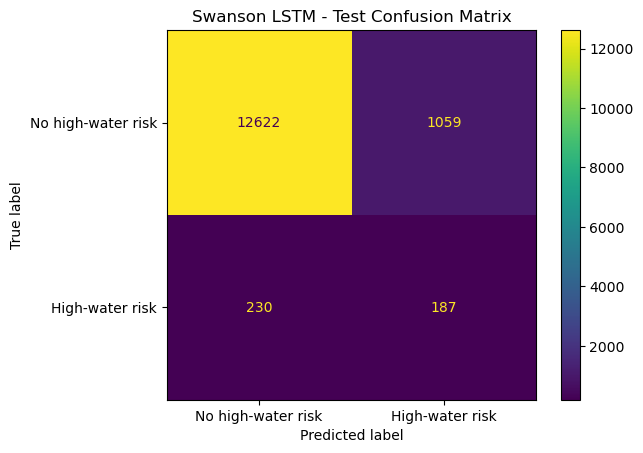

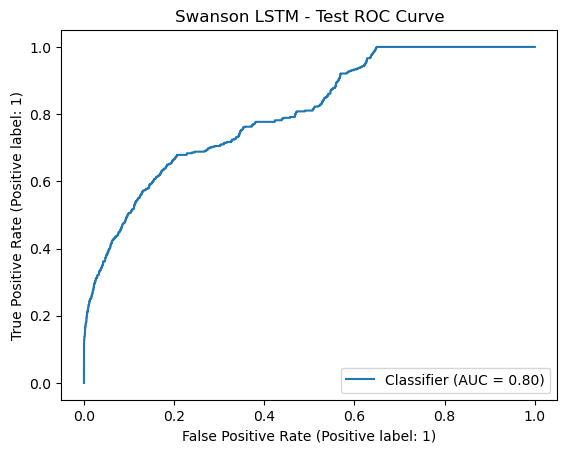

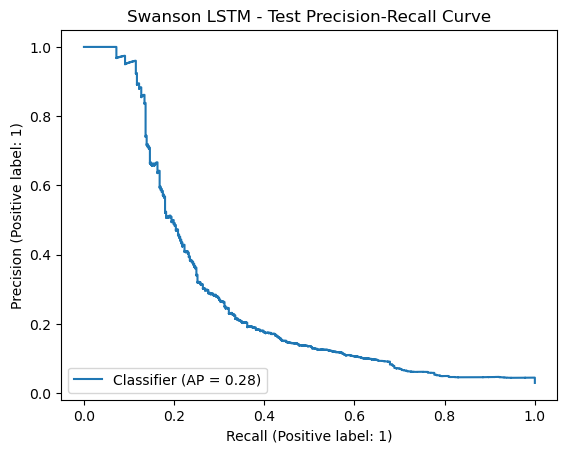

In [20]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions_binary,
    display_labels=[
        "No high-water risk",
        "High-water risk"
    ],
    values_format="d"
)

plt.title(
    "Swanson LSTM - Test Confusion Matrix"
)
plt.show()

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities
)
plt.title(
    "Swanson LSTM - Test ROC Curve"
)
plt.show()

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities
)
plt.title(
    "Swanson LSTM - Test Precision-Recall Curve"
)
plt.show()


## 16. Hourly Test Predictions

In [21]:

test_predictions = pd.DataFrame({
    "timestamp": pd.to_datetime(
        test_timestamps
    ),
    "actual_risk": y_test.astype(int),
    "risk_probability": test_probabilities,
    "predicted_risk": test_predictions_binary.astype(int),
})

display(
    test_predictions.head()
)

print(
    "Prediction rows:",
    len(test_predictions)
)


,timestamp,actual_risk,risk_probability,predicted_risk
0,2024-05-08 05:00:00,0,0.117538,0
1,2024-05-08 06:00:00,0,0.117428,0
2,2024-05-08 07:00:00,0,0.117360,0
3,2024-05-08 08:00:00,0,0.117317,0
4,2024-05-08 09:00:00,0,0.117163,0


Prediction rows: 14098



## 17. Episode-Level Diagnostic Evaluation

Consecutive positive target hours are grouped into model-defined high-water-risk episodes.

An episode is counted as detected if the LSTM produces at least one positive prediction during that episode.

This is a diagnostic measure of **high-water-risk episode detection**, not verification of officially recorded historical floods.


In [22]:

full_test_target = (
    model_data.loc[
        model_data[
            "data_period"
        ].eq("test")
        & model_data[
            "flood_next_24h"
        ].notna(),
        [
            "timestamp",
            "flood_next_24h",
        ]
    ]
    .rename(
        columns={
            "flood_next_24h":
            "actual_risk"
        }
    )
    .copy()
)

full_test_target["actual_risk"] = (
    full_test_target[
        "actual_risk"
    ]
    .astype(int)
)

event_frame = (
    full_test_target
    .merge(
        test_predictions[
            [
                "timestamp",
                "risk_probability",
                "predicted_risk",
            ]
        ],
        on="timestamp",
        how="left"
    )
    .sort_values(
        "timestamp"
    )
    .reset_index(
        drop=True
    )
)

event_frame[
    "predicted_risk_for_detection"
] = (
    event_frame[
        "predicted_risk"
    ]
    .fillna(0)
    .astype(int)
)

actual_positive = (
    event_frame[
        "actual_risk"
    ]
    == 1
)

timestamp_gap = (
    event_frame[
        "timestamp"
    ]
    .diff()
    .ne(
        pd.Timedelta(
            hours=1
        )
    )
)

new_event = (
    actual_positive
    & (
        ~actual_positive.shift(
            fill_value=False
        )
        | timestamp_gap
    )
)

event_frame[
    "event_id"
] = (
    new_event
    .cumsum()
    .where(
        actual_positive
    )
)

event_level_results = (
    event_frame.loc[
        actual_positive
    ]
    .groupby(
        "event_id"
    )
    .agg(
        event_start=(
            "timestamp",
            "min"
        ),
        event_end=(
            "timestamp",
            "max"
        ),
        event_duration_hours=(
            "timestamp",
            "size"
        ),
        detected_hours=(
            "predicted_risk_for_detection",
            "sum"
        ),
        maximum_risk_score=(
            "risk_probability",
            "max"
        ),
        mean_risk_score=(
            "risk_probability",
            "mean"
        ),
    )
    .reset_index()
)

event_level_results[
    "event_detected"
] = (
    event_level_results[
        "detected_hours"
    ]
    > 0
)

event_level_results[
    "hourly_detection_percentage"
] = (
    100
    * event_level_results[
        "detected_hours"
    ]
    / event_level_results[
        "event_duration_hours"
    ]
)

display(
    event_level_results
)

event_detection_rate = (
    event_level_results[
        "event_detected"
    ]
    .mean()
    * 100
)

print(
    "\nEvent detection rate:",
    round(
        event_detection_rate,
        2
    ),
    "%"
)


,event_id,event_start,event_end,event_duration_hours,detected_hours,maximum_risk_score,mean_risk_score,event_detected,hourly_detection_percentage
0,1.0,2024-06-13 08:00:00,2024-06-14 08:00:00,25,9,0.967917,0.570496,True,36.000000
1,2.0,2024-08-31 04:00:00,2024-09-01 05:00:00,26,13,0.983717,0.664993,True,50.000000
2,3.0,2025-04-19 19:00:00,2025-04-20 18:00:00,24,11,0.965975,0.619109,True,45.833333
3,4.0,2025-05-01 13:00:00,2025-05-02 14:00:00,26,13,0.976052,0.660254,True,50.000000
4,5.0,2025-05-08 18:00:00,2025-05-09 19:00:00,26,16,0.982604,0.682751,True,61.538462
5,6.0,2025-06-09 21:00:00,2025-06-11 01:00:00,29,16,0.994027,0.714652,True,55.172414
6,7.0,2025-06-26 11:00:00,2025-06-27 11:00:00,25,5,0.982638,0.566503,True,20.000000
7,8.0,2025-07-09 12:00:00,2025-07-11 21:00:00,58,36,0.995950,0.698526,True,62.068966
8,9.0,2025-07-16 09:00:00,2025-07-17 17:00:00,33,14,0.983224,0.671884,True,42.424242
9,10.0,2025-07-28 13:00:00,2025-07-30 01:00:00,37,21,0.994106,0.728920,True,56.756757



Event detection rate: 100.0 %


## 18. Save Model and Outputs

The shared consolidated input dataset `swanson_lstm_hourly.csv` was exported earlier in the notebook.

In [23]:

output_dir = (
    Path("outputs")
    / "swanson_lstm"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

torch.save(
    {
        "model_state_dict":
            model.state_dict(),
        "lookback_hours":
            LOOKBACK_HOURS,
        "feature_columns":
            feature_columns,
        "selected_probability_threshold":
            selected_probability_threshold,
        "high_water_threshold_m":
            float(
                high_water_threshold
            ),
    },
    output_dir
    / "swanson_lstm_model.pt"
)

joblib.dump(
    scaler,
    output_dir
    / "swanson_lstm_scaler.pkl"
)

test_predictions.to_csv(
    output_dir
    / "swanson_lstm_test_predictions.csv",
    index=False
)

event_level_results.to_csv(
    output_dir
    / "swanson_lstm_event_level_results.csv",
    index=False
)

validation_metrics.to_frame(
    "value"
).to_csv(
    output_dir
    / "swanson_lstm_validation_metrics.csv"
)

test_metrics.to_frame(
    "value"
).to_csv(
    output_dir
    / "swanson_lstm_test_metrics.csv"
)

history_df.to_csv(
    output_dir
    / "swanson_lstm_training_history.csv",
    index=False
)

print(
    "Saved outputs to:",
    output_dir.resolve()
)


Saved outputs to: C:\Users\lauso\AA Capstone Project\outputs\swanson_lstm
